## Dati come immagini

### Un'immagine è una griglia di numeri

Un'immagine digitale è una griglia rettangolare di piccoli elementi chiamati **pixel** (*picture elements*). Per ogni pixel memorizziamo uno o più numeri che ne descrivono l'intensità o il colore.

Indichiamo con $M$ il numero di **righe** (altezza) e con $N$ il numero di **colonne** (larghezza): l'immagine contiene $MN$ pixel. In NumPy si accede al pixel con `immagine[i, j]`, indicando **prima la riga e poi la colonna**. Gli indici partono da zero; nelle visualizzazioni seguenti il pixel `[0, 0]` è in alto a sinistra.

La differenza fondamentale è nel numero di valori associati a ciascun pixel:

- un'immagine **grayscale**, o in scala di grigi, ha un valore per pixel;
- un'immagine a colori **RGB** ha tre valori per pixel: rosso, verde e blu.

### 1. Immagini grayscale: una matrice

Un'immagine in scala di grigi si rappresenta con una matrice $G\in\mathbb{R}^{M\times N}$. Nel formato comune **a 8 bit**, ciascun valore è un intero compreso tra $0$ e $255$:

- $0$ corrisponde al nero;
- $255$ corrisponde al bianco;
- i valori intermedi corrispondono a grigi progressivamente più chiari.

Gli 8 bit permettono di rappresentare $2^8=256$ livelli. In NumPy il tipo corrispondente è `uint8`, cioè intero senza segno a 8 bit. Non tutte le immagini usano questo formato: esistono anche rappresentazioni a 16 bit o in virgola mobile.

Consideriamo questa piccola immagine di $4\times4=16$ pixel:

$$G=\begin{pmatrix}
0&0&255&255\\
0&64&192&255\\
64&128&192&255\\
255&192&128&0
\end{pmatrix}.$$

**Ogni elemento della matrice determina il grigio di una casella.** Cambiare un elemento significa cambiare il pixel corrispondente. Nell'esempio modifichiamo `G[1, 1]`, cioè il pixel della seconda riga e della seconda colonna, da $64$ a $255$.

Forma (righe, colonne): (4, 4)
Tipo: uint8 — memoria dei pixel: 16 byte
Pixel G[1, 1]: 64 → 255


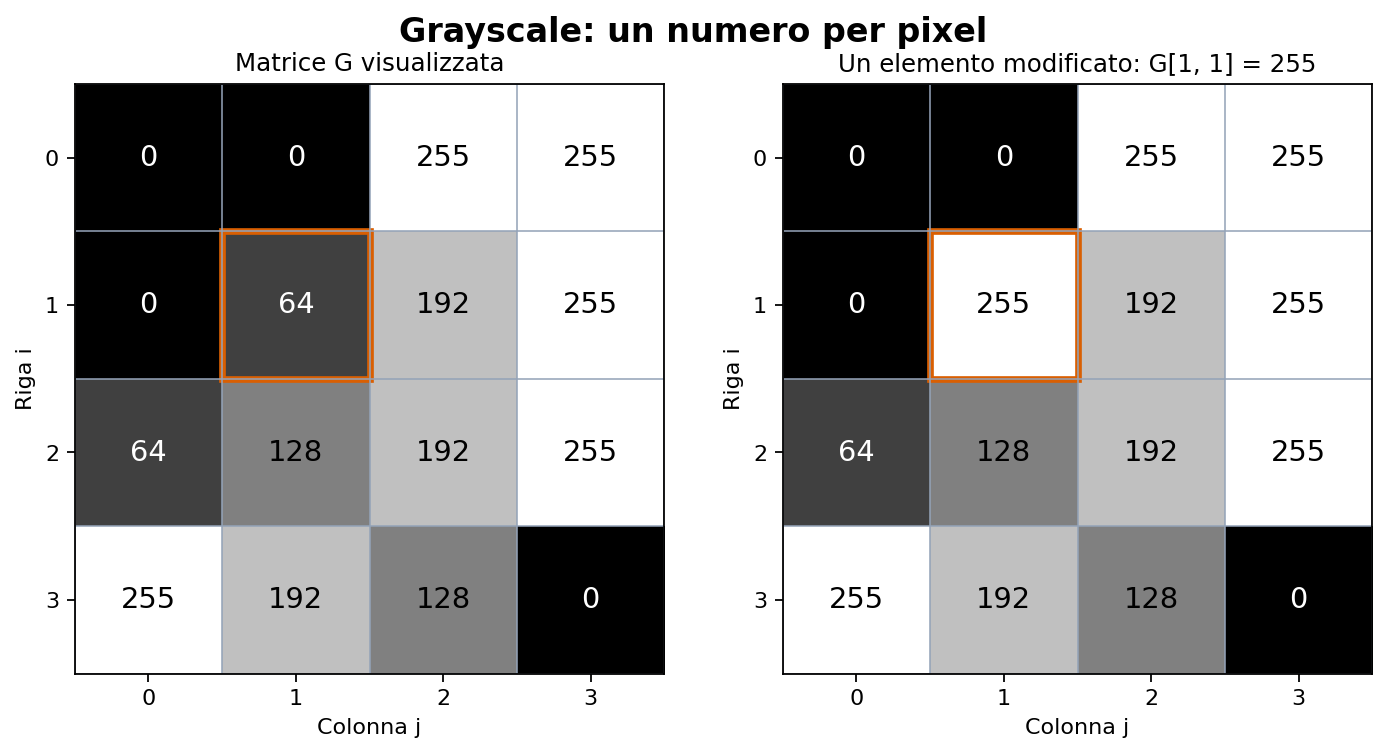

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

G = np.array([
    [0,   0,   255, 255],
    [0,   64,  192, 255],
    [64,  128, 192, 255],
    [255, 192, 128, 0]
], dtype=np.uint8)

G_modificata = G.copy()  # Mantieni anche la matrice originale
G_modificata[1, 1] = 255

print("Forma (righe, colonne):", G.shape)
print("Tipo:", G.dtype, "— memoria dei pixel:", G.nbytes, "byte")
print("Pixel G[1, 1]:", G[1, 1], "→", G_modificata[1, 1])

fig, assi = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, A, titolo in zip(assi, [G, G_modificata],
                        ["Matrice G visualizzata", "Un elemento modificato: G[1, 1] = 255"]):
    # La scala è fissata per confrontare correttamente le intensità
    ax.imshow(A, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, str(A[i, j]), ha="center", va="center",
                    color="white" if A[i, j] < 128 else "black", fontsize=13)
    ax.add_patch(Rectangle((0.5, 0.5), 1, 1, fill=False,
                           edgecolor="#D95F02", linewidth=3))
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
    ax.grid(which="minor", color="#94A3B8", linewidth=0.7)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_xlabel("Colonna j")
    ax.set_ylabel("Riga i")
    ax.set_title(titolo, fontsize=11)
fig.suptitle("Grayscale: un numero per pixel", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

I numeri scritti nei quadrati sono annotazioni aggiunte per leggere la figura: **non fanno parte dell'immagine**. L'immagine contiene soltanto i 16 valori della matrice.

Il parametro `cmap="gray"` visualizza i numeri come livelli di grigio. Senza questa scelta, Matplotlib può associare ai numeri falsi colori. Impostando `vmin=0, vmax=255`, il valore $0$ rimane nero e $255$ rimane bianco in entrambi i pannelli.

### 2. Immagini RGB: tre matrici, un colore per pixel

Per descrivere il colore usiamo tre componenti: **R** (*Red*, rosso), **G** (*Green*, verde) e **B** (*Blue*, blu). Nel formato RGB a 8 bit per canale, ogni componente varia da $0$ a $255$.

| Terna $(R,G,B)$ | Colore |
|---|---|
| $(0,0,0)$ | Nero |
| $(255,255,255)$ | Bianco |
| $(255,0,0)$ | Rosso |
| $(0,255,0)$ | Verde |
| $(0,0,255)$ | Blu |
| $(255,255,0)$ | Giallo |
| $(128,128,128)$ | Grigio intermedio |

Un'immagine RGB di $M\times N$ pixel è quindi memorizzata, nella rappresentazione NumPy usata qui, come un **array di forma $(M,N,3)$**. La terza dimensione identifica il canale: `0` per R, `1` per G, `2` per B.

$$I[i,j,:]=\bigl(R[i,j],\ G[i,j],\ B[i,j]\bigr).$$

Creiamo un'immagine di **2 righe e 3 colonne**, quindi appena **6 pixel**: rosso, verde e blu nella prima riga; giallo, bianco e nero nella seconda. I suoi tre canali sono

$$R=\begin{pmatrix}255&0&0\\255&255&0\end{pmatrix},\quad
G=\begin{pmatrix}0&255&0\\255&255&0\end{pmatrix},\quad
B=\begin{pmatrix}0&0&255\\0&255&0\end{pmatrix}.$$

Per esempio, il pixel giallo ha coordinate `[1, 0]`: nello stesso punto troviamo $R=255$, $G=255$ e $B=0$. Le tre componenti insieme determinano il colore visualizzato.

Forma (righe, colonne, canali): (2, 3, 3)
Numero di pixel: 6
Numero di valori memorizzati: 18
Memoria dei pixel: 18 byte
Terna del pixel giallo RGB[1, 0]: [255 255   0]
Componente rossa RGB[1, 0, 0]: 255


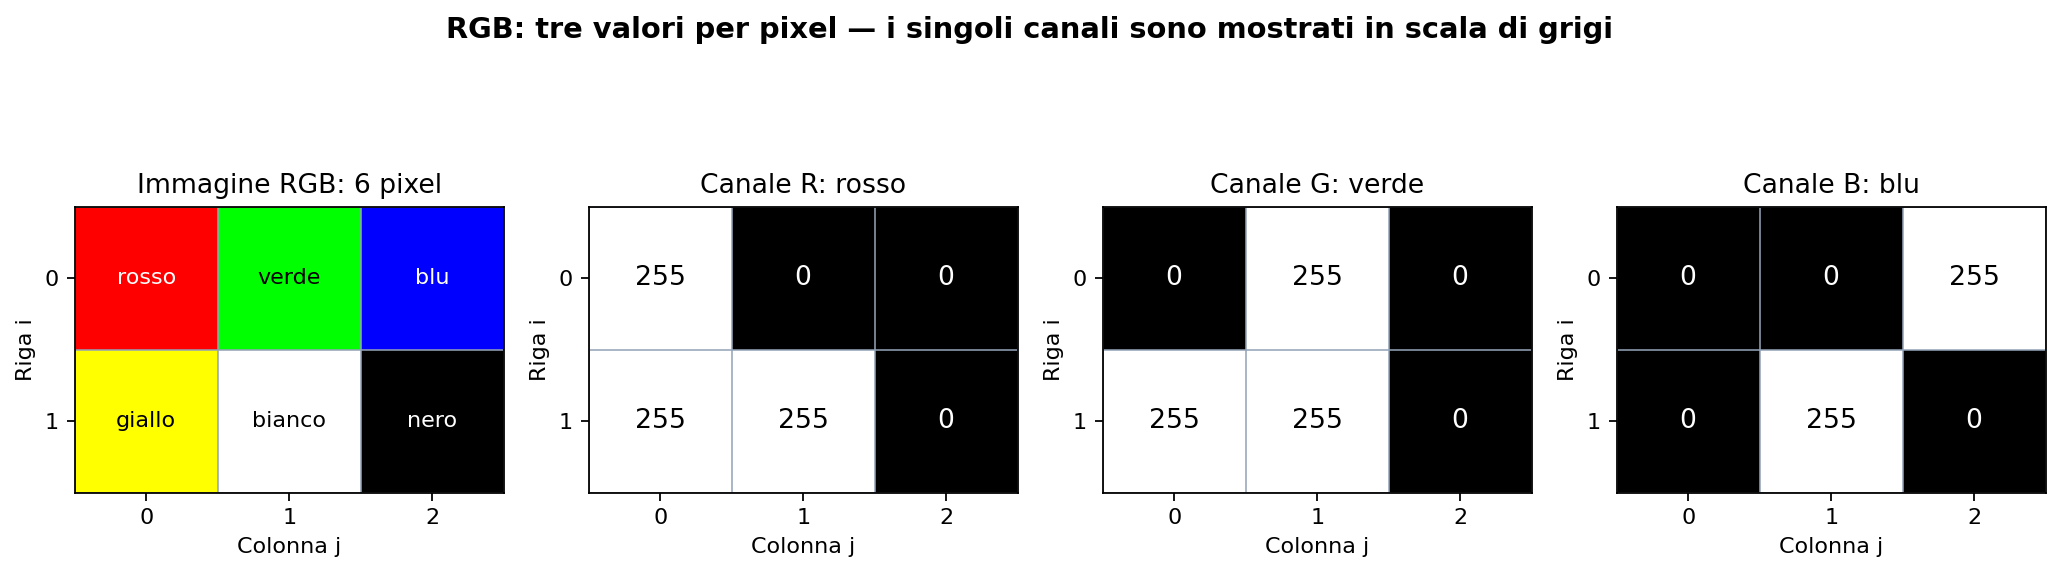

In [2]:
RGB = np.array([
    [[255, 0, 0],   [0, 255, 0],     [0, 0, 255]],
    [[255, 255, 0], [255, 255, 255], [0, 0, 0]]
], dtype=np.uint8)

print("Forma (righe, colonne, canali):", RGB.shape)
print("Numero di pixel:", RGB.shape[0] * RGB.shape[1])
print("Numero di valori memorizzati:", RGB.size)
print("Memoria dei pixel:", RGB.nbytes, "byte")
print("Terna del pixel giallo RGB[1, 0]:", RGB[1, 0])
print("Componente rossa RGB[1, 0, 0]:", RGB[1, 0, 0])

fig, assi = plt.subplots(1, 4, figsize=(13, 4))
assi[0].imshow(RGB, interpolation="nearest")
assi[0].set_title("Immagine RGB: 6 pixel")
nomi = [["rosso", "verde", "blu"], ["giallo", "bianco", "nero"]]
for i in range(2):
    for j in range(3):
        colore = "white" if (i, j) in [(0, 0), (0, 2), (1, 2)] else "black"
        assi[0].text(j, i, nomi[i][j], ha="center", va="center",
                     color=colore, fontsize=10)

for c, nome in enumerate(["R: rosso", "G: verde", "B: blu"]):
    canale = RGB[:, :, c]  # Tutte le righe e le colonne, un solo canale
    ax = assi[c + 1]
    ax.imshow(canale, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(f"Canale {nome}")
    for i in range(2):
        for j in range(3):
            ax.text(j, i, str(canale[i, j]), ha="center", va="center",
                    color="white" if canale[i, j] < 128 else "black", fontsize=12)

for ax in assi:
    ax.set_xticks(range(3))
    ax.set_yticks(range(2))
    ax.set_xlabel("Colonna j")
    ax.set_ylabel("Riga i")
    ax.set_xticks(np.arange(-0.5, 3, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="#94A3B8", linewidth=0.7)
    ax.tick_params(which="minor", bottom=False, left=False)
fig.suptitle("RGB: tre valori per pixel — i singoli canali sono mostrati in scala di grigi",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Come leggere i canali:** nei tre pannelli in scala di grigi, una casella bianca indica che quel canale vale $255$; una casella nera indica che vale $0$. Il bianco nel pannello R significa quindi “componente rossa massima”, non “pixel RGB bianco”. Il colore finale dipende da **tutti e tre** i valori.

Per accedere ai dati:

| Espressione | Significato | Forma del risultato nell'esempio |
|---|---|---|
| `RGB[1, 0]` | Tutta la terna del pixel giallo | `(3,)` |
| `RGB[1, 0, 0]` | Componente rossa di quel pixel | Scalare |
| `RGB[:, :, 0]` | Matrice del canale rosso | `(2, 3)` |
| `RGB[0, :, :]` | Prima riga di pixel, tutti i canali | `(3, 3)` |

Per trasformare il pixel giallo in magenta basta assegnare `RGB[1, 0] = [255, 0, 255]`: si modifica una terna di numeri.

### 3. Quanta memoria serve?

Un **byte** contiene 8 bit. Con il tipo `uint8`, ogni valore occupa un byte: un pixel grayscale richiede un byte, un pixel RGB ne richiede tre.

| Rappresentazione | Forma dell'array | Valori per pixel | Memoria dei dati `uint8` |
|---|---|---:|---:|
| Grayscale | $(M,N)$ | 1 | $MN$ byte |
| RGB | $(M,N,3)$ | 3 | $3MN$ byte |

Nell'esempio grayscale memorizziamo $4\cdot4=16$ valori, quindi **16 byte**. Nell'esempio RGB i pixel sono $2\cdot3=6$, ma i valori sono $2\cdot3\cdot3=18$, quindi **18 byte**. Non bisogna confondere il numero di pixel con il numero di valori memorizzati.

Per un'immagine di $1000\times1000$ pixel servono **1 MB** in grayscale oppure **3 MB** in RGB, usando $1\text{ MB}=10^6$ byte. Questi conti riguardano i dati dell'array non compressi, senza i metadati: la dimensione di un file PNG o JPEG può essere diversa perché dipende anche dal formato e dalla compressione.

### 4. Dai valori interi ai calcoli sull'immagine

Per eseguire operazioni numeriche è spesso utile convertire i dati in virgola mobile e, nel caso a 8 bit, normalizzarli nell'intervallo $[0,1]$:

$$G_{\mathrm{float}}[i,j]=\frac{G[i,j]}{255}.$$

Il nero diventa $0$, il bianco diventa $1$. Cambiano tipo e scala numerica, mentre la griglia dei pixel rimane la stessa. Un valore `float32` occupa 4 byte, quindi l'array richiede quattro volte la memoria dell'equivalente `uint8`.

**Prima di somme e sottrazioni, convertiamo gli interi in float:** l'aritmetica direttamente su `uint8` può produrre overflow o underflow, perché i risultati non sono rappresentabili oltre l'intervallo $[0,255]$.

In [3]:
G_float = G.astype(np.float32) / 255.0
RGB_float = RGB.astype(np.float32) / 255.0

print("Grayscale normalizzata:")
print(np.round(G_float, 3))
print("Forma:", G_float.shape, "— tipo:", G_float.dtype)
print("Memoria:", G_float.nbytes, "byte, contro", G.nbytes, "byte in uint8")
print("Giallo normalizzato:", RGB_float[1, 0])

Grayscale normalizzata:
[[0.    0.    1.    1.   ]
 [0.    0.251 0.753 1.   ]
 [0.251 0.502 0.753 1.   ]
 [1.    0.753 0.502 0.   ]]
Forma: (4, 4) — tipo: float32
Memoria: 64 byte, contro 16 byte in uint8
Giallo normalizzato: [1. 1. 0.]


### Dalle piccole matrici a una fotografia

Una fotografia usa la stessa rappresentazione dei nostri esempi, ma con molte più righe e colonne. Carichiamo `peppers1.tif` e normalizziamo i valori: mostreremo **prima gli esempi in scala di grigi, poi quelli a colori**. Passeremo infine alla convoluzione, che combina i valori di pixel vicini.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Leggi l'immagine: i canali sono già in ordine RGB
img = plt.imread("immagini_sorgente/peppers1.tif")

print(f"Minimo assoluto: {np.min(img)}")
print(f"Massimo assoluto: {np.max(img)}")

# Converti in float e normalizza se l'immagine ha valori interi
if np.issubdtype(img.dtype, np.integer):
    img2 = img.astype(np.float32) / np.iinfo(img.dtype).max
else:
    img2 = img.astype(np.float32)  # Si assumono valori già in [0, 1]


Minimo assoluto: 0
Massimo assoluto: 229


### Trasformazioni su un’immagine grayscale

Iniziamo da una versione in scala di grigi di `peppers`. Usiamo `img2`, caricata e normalizzata in $[0,1]$ nella cella precedente, e combiniamo i canali con una somma pesata:

$$I_{\mathrm{gray}}=0.2126\,R+0.7152\,G+0.0722\,B.$$

Questa conversione fornisce una rappresentazione in grigi con maggiore peso al verde. Qui la usiamo direttamente sui valori RGB normalizzati per una visualizzazione didattica; il calcolo della luminanza fisica di un'immagine sRGB richiederebbe prima la linearizzazione dei canali.

Il risultato è una **matrice bidimensionale** di forma $(M,N)$: un solo valore per pixel. Se `img2` è già grayscale, possiamo usarla direttamente.

**Figure già disponibili.** I tre confronti seguenti sono salvati nel notebook e si vedono senza eseguire il codice. Per generarli qui è stato utilizzato il riquadro originale di `peppers` già presente nell’output del notebook, alla risoluzione di $356\times356$ pixel. Non si tratta del TIFF originale: eseguendo le celle con `immagini_sorgente/peppers1.tif`, i risultati vengono ricalcolati alla risoluzione del file caricato.


In [ ]:
# Eseguire dopo la cella che carica peppers e definisce img2.
if img2.ndim == 3:
    img_gray = (
        0.2126 * img2[:, :, 0]
        + 0.7152 * img2[:, :, 1]
        + 0.0722 * img2[:, :, 2]
    )
else:
    img_gray = img2.copy()

print("Forma dell'immagine di partenza:", img2.shape)
print("Forma dell'immagine grayscale:", img_gray.shape)
print(f"Intervallo dei valori: [{img_gray.min():.3f}, {img_gray.max():.3f}]")

Forma dell'immagine di partenza: (356, 356, 3)
Forma dell'immagine grayscale: (356, 356)
Intervallo dei valori: [0.008, 0.868]


#### Luminosità e negativo

Applichiamo tre semplici trasformazioni alle intensità dei pixel:

- **Scurimento:** $J=\operatorname{clip}(I-0.5,0,1)$.
- **Schiarimento:** $J=\operatorname{clip}(I+0.5,0,1)$.
- **Negativo:** $J=1-I$; le zone chiare diventano scure e viceversa.

`clip` tronca i valori sotto $0$ e sopra $1$. In tutti i grafici fissiamo **`cmap="gray", vmin=0, vmax=1`**: senza una scala comune, il ridimensionamento automatico dei livelli potrebbe nascondere le differenze di luminosità.

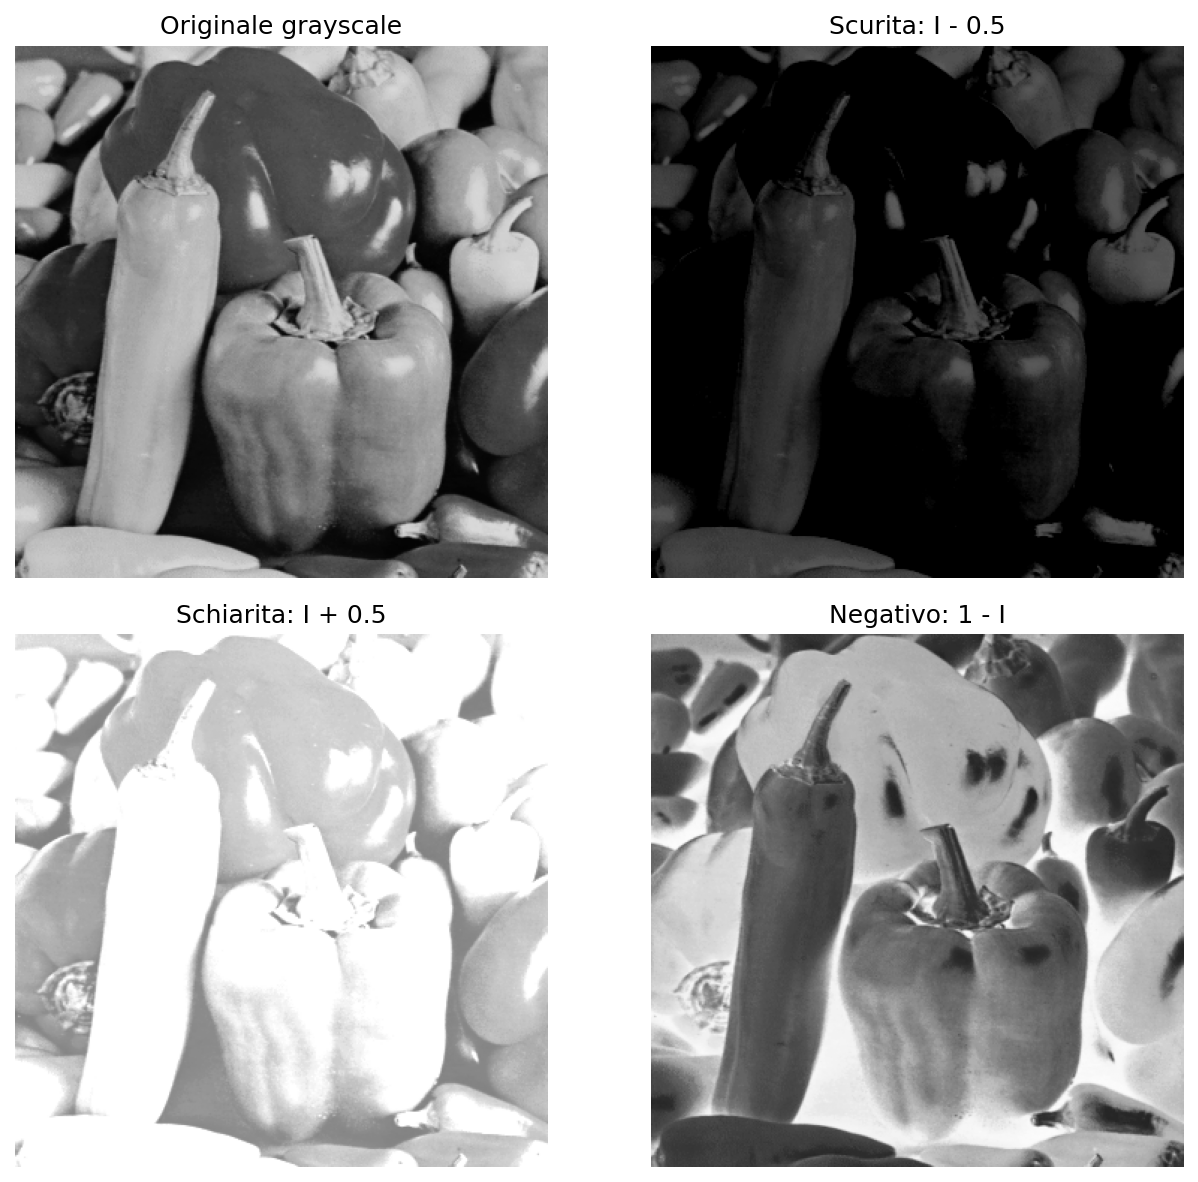

In [ ]:
gray_scura = np.clip(img_gray - 0.5, 0, 1)
gray_chiara = np.clip(img_gray + 0.5, 0, 1)
gray_negativa = 1 - img_gray

fig, assi = plt.subplots(2, 2, figsize=(9, 8))
immagini_gray = [img_gray, gray_scura, gray_chiara, gray_negativa]
titoli_gray = ["Originale grayscale", "Scurita: I - 0.5",
               "Schiarita: I + 0.5", "Negativo: 1 - I"]

for ax, immagine, titolo in zip(assi.ravel(), immagini_gray, titoli_gray):
    ax.imshow(immagine, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titolo)
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Contrasto, trasformazione gamma e sogliatura

- **Contrasto aumentato:** allontaniamo le intensità dal livello $0.5$ usando $J=\operatorname{clip}(0.5+2(I-0.5),0,1)$.
- **Trasformazione gamma:** $J=I^{0.5}=\sqrt{I}$ aumenta i valori intermedi, schiarendo soprattutto le zone scure.
- **Sogliatura:** $J_{i,j}=1$ se $I_{i,j}\geq0.5$, e $J_{i,j}=0$ altrimenti. Otteniamo un'immagine binaria, con soli pixel bianchi e neri.

Queste operazioni agiscono su ogni valore della matrice indipendentemente dai pixel vicini.

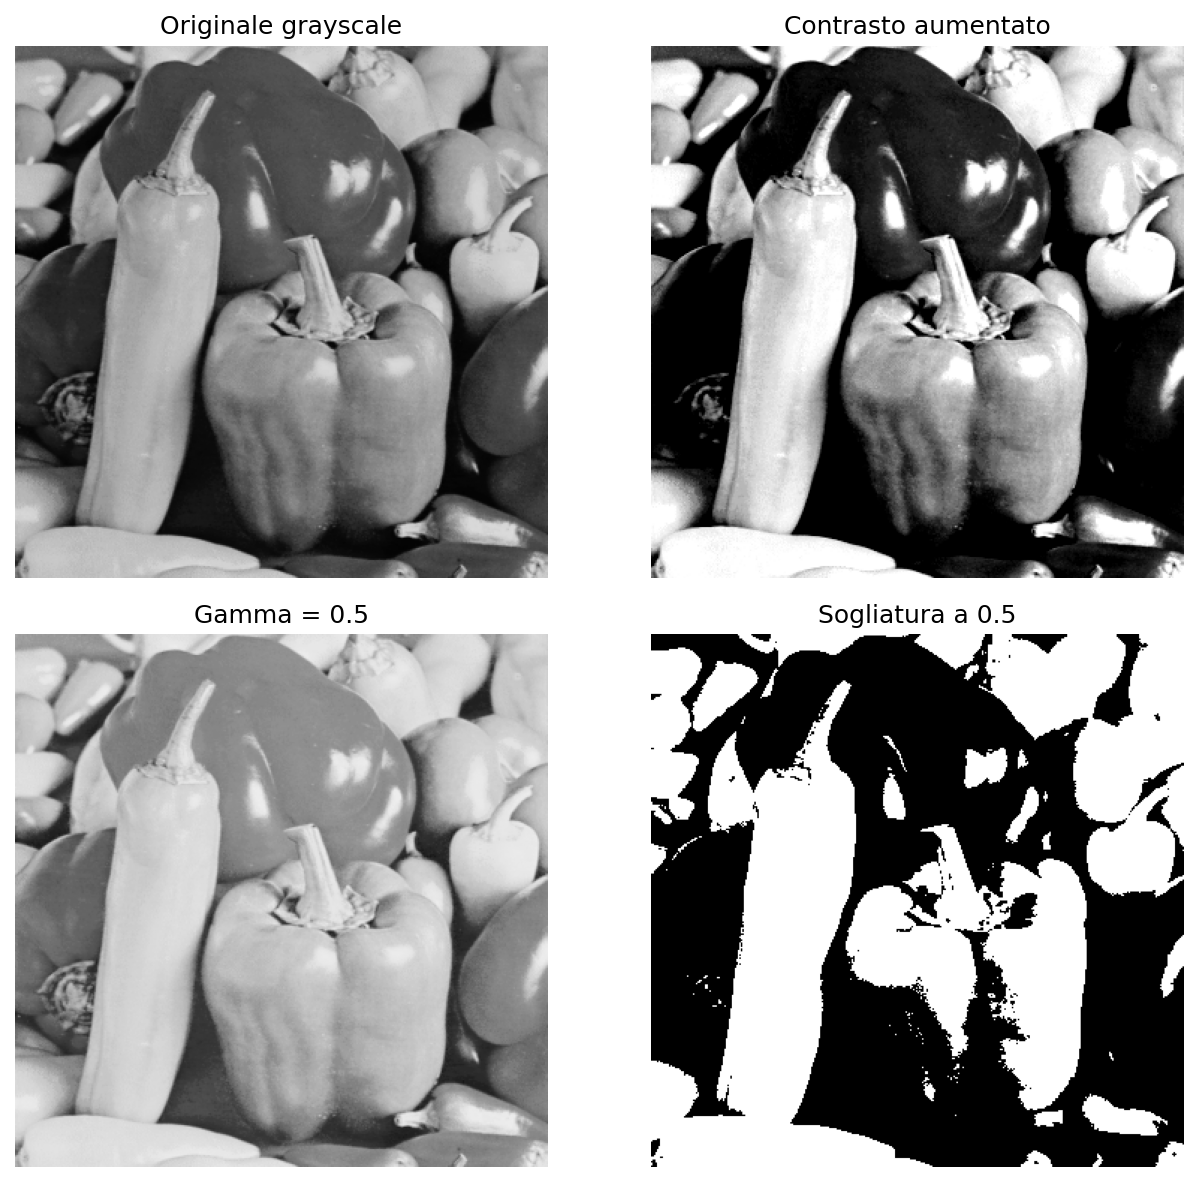

In [ ]:
gray_contrasto = np.clip(0.5 + 2 * (img_gray - 0.5), 0, 1)
gray_gamma = np.sqrt(img_gray)
gray_binaria = (img_gray >= 0.5).astype(float)

fig, assi = plt.subplots(2, 2, figsize=(9, 8))
immagini_gray = [img_gray, gray_contrasto, gray_gamma, gray_binaria]
titoli_gray = ["Originale grayscale", "Contrasto aumentato",
               "Gamma = 0.5", "Sogliatura a 0.5"]

for ax, immagine, titolo in zip(assi.ravel(), immagini_gray, titoli_gray):
    ax.imshow(immagine, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titolo)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Gli stessi esempi sull’immagine a colori

Ripetiamo ora le trasformazioni su `img2`, l’immagine RGB normalizzata. Le operazioni di luminosità, negativo, contrasto e gamma vengono applicate separatamente ai tre canali. Per la sogliatura convertiamo prima l’immagine in scala di grigi.


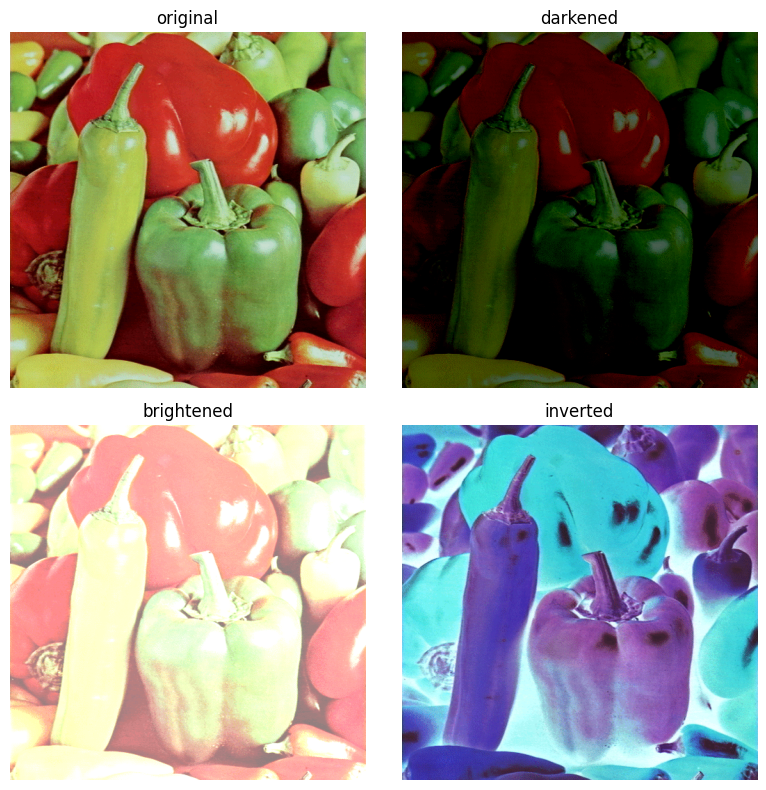

In [ ]:
plt.figure(figsize=(8, 8))

plt.subplot(221)
plt.imshow(img2)
plt.title("original")
plt.axis("off")

plt.subplot(222)
img_d = np.clip(img2 - 0.5, 0, 1)
plt.imshow(img_d)
plt.title("darkened")
plt.axis("off")

plt.subplot(223)
img_b = np.clip(img2 + 0.5, 0, 1)
plt.imshow(img_b)
plt.title("brightened")
plt.axis("off")

plt.subplot(224)
plt.imshow(1 - img2)
plt.title("inverted")
plt.axis("off")

plt.tight_layout()
plt.show()

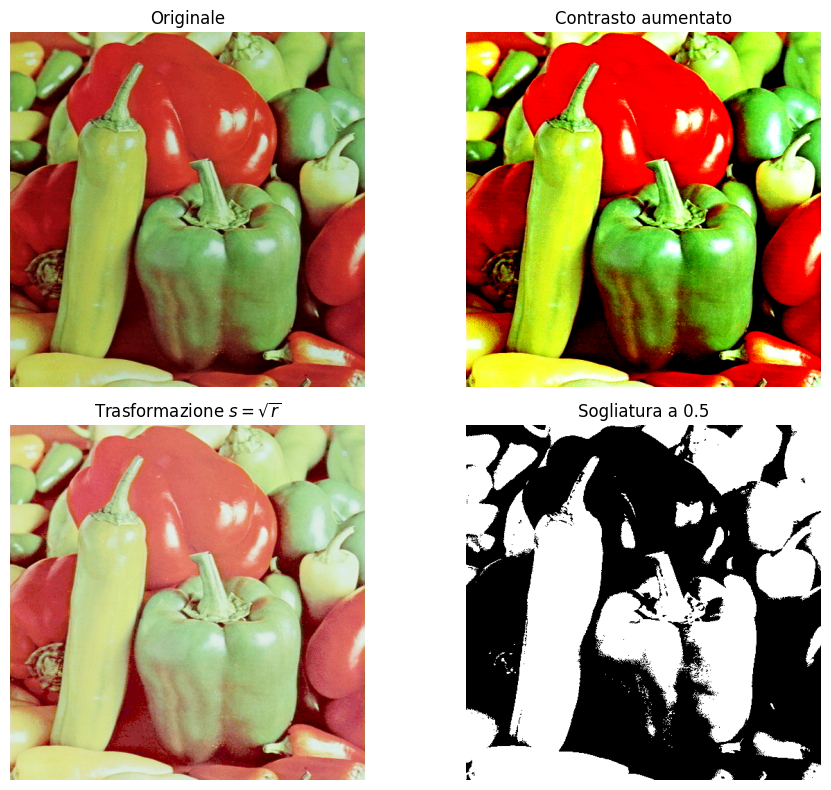

In [12]:
# Aumento del contrasto rispetto al livello intermedio 0.5
img_contrasto = np.clip(0.5 + 2 * (img2 - 0.5), 0, 1)

# Trasformazione non lineare: schiarisce soprattutto i valori bassi
img_gamma = img2**0.5

# Conversione da RGB a scala di grigi
img_grigia = (
    0.2126 * img2[:, :, 0]
    + 0.7152 * img2[:, :, 1]
    + 0.0722 * img2[:, :, 2]
)

# Sogliatura: ogni pixel diventa bianco oppure nero
img_binaria = (img_grigia >= 0.5).astype(float)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

immagini = [img2, img_contrasto, img_gamma, img_binaria]
titoli = [
    "Originale",
    "Contrasto aumentato",
    r"Trasformazione $s=\sqrt{r}$",
    "Sogliatura a 0.5"
]

for ax, immagine, titolo in zip(axes.ravel(), immagini, titoli):
    ax.imshow(immagine, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titolo)
    ax.axis("off")

plt.tight_layout()
plt.show()

Queste trasformazioni calcolano ogni pixel di uscita usando soltanto il pixel corrispondente; la convoluzione combina invece i valori di un intorno.

### Convoluzione

In generale, la convoluzione è
un'operazione matematica (simbolo: *)
che, date due funzioni, ne produce una
terza che è calcolata come segue:

$$
 (f*g)(t)=\int{f(\tau)g(t-\tau)d\tau}
 $$

Nell'imaging, $f$ e $g$ sono funzioni discrete bidimensionali, cioè 
matrici,corrispondenti ad immagini.
La convoluzione discreta 2D diventa quindi:

$$
(f*g)(x,y)=\sum_{i=0}^M \sum_{j=1}^N f(x,y) g(x-i,y-j), \ \ x,y=0, \ldots N
$$ 

L'applicazione delle convoluzioni in imaging
può essere più facilmente spiegata
graficamente come segue:

- consideriamo una matrice $K$ di dimensione  nxn (di solito n è dispari) il cui punto centrale viene fatto coincidere con un pixel dell'immagine $f$ a cui applicare la convoluzione
- moltiplichiamo i valori nella matrice con i valori dei
pixel corrispondenti, e sommiamo tutti i risultati
- ll valore ottenuto è il valore del pixel centrale nel
risultato
- l'operazione viene ripetuta (spostando la matrice)
per tutti i pixel dell'immagine


All'interno del contesto di questa definizione, la matrice $K$ prenderà il nome di **nucleo di convoluzione** o **kernel di convoluzione**

![](immagini_sorgente/conv.png)

### Pratica guida alla convoluzione di immagini

Mostriamo un esempio di come applicare le definizioni sinora presentate.

In primo luogo, come già evidenziato precedentemente, un immagine non è altro che una matrice (di qualche dimensione) i cui coefficienti rappresentato l'intensità di uno o più colori.

Dunque, assumiamo che la seguente immagine:

![alt-text](immagini_sorgente/bc_zero_cropped.png)

sia la nostra matrice $A$.

E supponiamo che la seguente matrice, sia il nostro nucleo di convoluzione $K$:

![alt-text](immagini_sorgente/fig103_ker.png)

Adesso dobbiamo scegliere come estendere la matrice $A$. Ecco alcune opzioni:

![alt-text](immagini_sorgente/cond_bordo.png)

tutti i diversi modi di estendere diversamente la matrice $A$ prendono il nome di: **condizioni al bordo**.


**ATTENZIONE**: la matrice $A$ ha dimensioni $503 \times 503$ e $K$ ha dimensioni $3 \times 3$, quindi ci occorre un estensione di $A$ di dimensioni $503 + (3-1) \times (503 + (3-1)$.
Ne segue, che le estensioni mostrate hanno dimensioni **ben più estese di quanto dovrebbero!** Sono solo da considerarsi come esempi utili di diverse condizioni al bordo. 

<!---**Attenzione**: la funzione di convoluzione $[K * (\cdot) \; | \; \mathcal{P}]$ **può** essere una funzione lineare. Vale a dire che **per delle opportune scelte del pattern di estensione $\mathcal{P}$**
potrà essere vero che, $\forall \; \alpha,\beta \in \mathbb{R}$:

$$ [K * (\alpha \; X + \beta \; Y) \; | \; \mathcal{P}] = \alpha \; [K * X \; | \; \mathcal{P}] + \beta \; [K * Y \; | \; \mathcal{P}] $$

di qui in avanti, si assumerà che qualunque sia il pattern di estensione $\mathcal{P}$ renda sempre la funzione di convoluzione lineare.---!>

<!---**Osservazione**: Poichè abbiamo presupposto che $[K * (\cdot) \; | \; \mathcal{P}]$ sia una funzione lineare. Allora, sappiamo che esiste un **unica** matrice $T$ di dimensioni $(N*M) \times (N*M)$, tale che:

$$T \, \mathcal{L}(X) = \mathcal{L}( \; [K * X \; | \; \mathcal{P}] \; )$$---!>

![alt text](immagini_sorgente/fig100_2.png)

In questo caso, il kernel utilizzato sostituisce il valore di ogni pixel con la media aritmetica dei valori contenuti nei quattro pixel ad esso adiacenti.

Ottenendo il seguente effetto di sfocatura:

![alt text](immagini_sorgente/fig103.png)

Consideriamo ora il seguente kernel:

![alt text](immagini_sorgente/kernel_bordi.png)

Osserviamo che, poichè la somma dei coefficienti è 0, sappiamo che se un pixel ha approssimativamente lo stesso colore dei quattro che
gli sono adiacenti, allora verrà rimpiazzato da un valore prossimo a zero; in altre parole, il pixer divverà di colore nero.

Ne segue che tutti e soli i pixel che avranno un valore non nullo, saranno quelli posizionati in mezzo a due regioni di colori contrastanti.
Pertanto, questo è un filtro che evidenzia i bordi dell'immagine

![alt text](immagini_sorgente/fig104.png)

Cosa succede infine se il filtro aumenta di dimensione?

### Filtri di media crescenti sull'immagine grayscale

Confrontiamo kernel $3\times3$, $7\times7$ e $15\times15$. Ogni kernel è

$$K=\frac{1}{n^2}\mathbf{1}_{n\times n}.$$

Poiché `img_gray` è una sola matrice, basta **una chiamata a `convolve2d` per ciascun kernel**, senza il ciclo sui canali RGB. `mode="same"` mantiene le dimensioni dell'immagine, mentre `boundary="symm"` usa un'estensione simmetrica ai bordi.

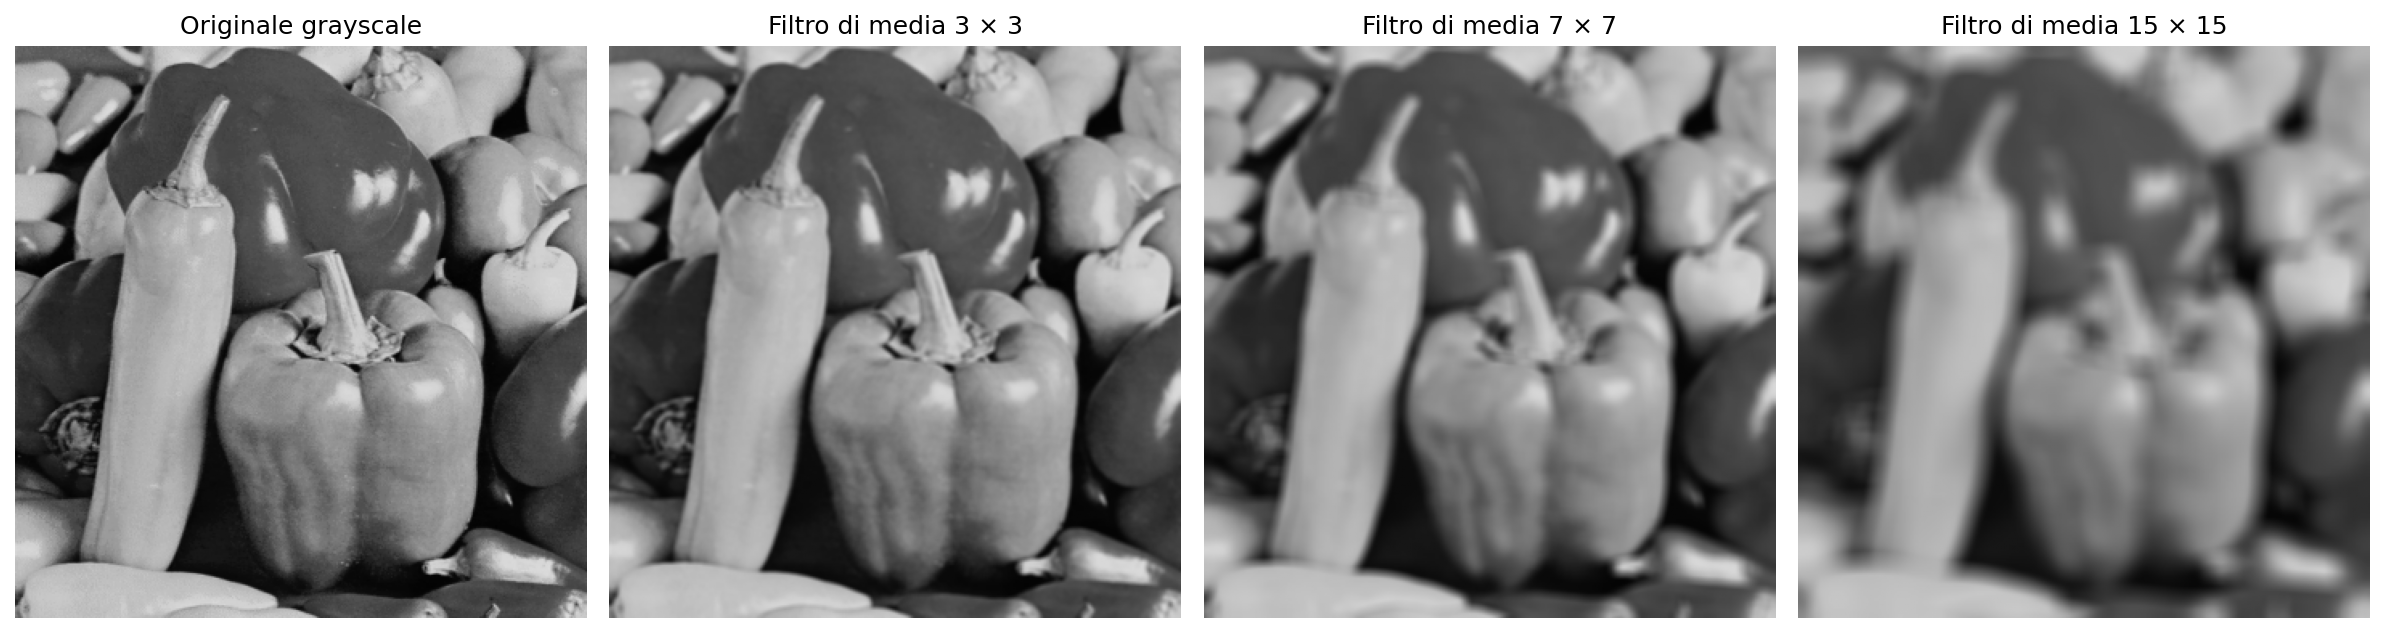

In [ ]:
from scipy.signal import convolve2d

dimensioni_gray = [3, 7, 15]
fig, assi = plt.subplots(1, 4, figsize=(16, 5))

assi[0].imshow(img_gray, cmap="gray", vmin=0, vmax=1)
assi[0].set_title("Originale grayscale")
assi[0].axis("off")

for ax, n in zip(assi[1:], dimensioni_gray):
    kernel_gray = np.ones((n, n), dtype=float) / n**2
    gray_filtrata = convolve2d(
        img_gray, kernel_gray, mode="same", boundary="symm"
    )
    ax.imshow(gray_filtrata, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Filtro di media {n} × {n}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Osservazione.** Aumentando la dimensione del kernel, ogni pixel dipende da un intorno più ampio: la sfocatura aumenta, le piccole strutture si attenuano e i contorni diventano meno netti. La somma dei coefficienti del kernel è $1$, quindi le regioni uniformi vengono preservate con le condizioni al bordo adottate.

**Da provare:** sostituire `[3, 7, 15]` con `[3, 15, 31]` e confrontare un dettaglio dell'immagine. Perché un filtro più grande rende meno distinguibili due strutture vicine?

### Filtri di media crescenti sull’immagine a colori

Ripetiamo il confronto sulla versione RGB di `peppers`, usando le stesse dimensioni del kernel. In questo caso applichiamo la convoluzione separatamente a ciascuno dei tre canali e poi ricomponiamo l’immagine a colori.


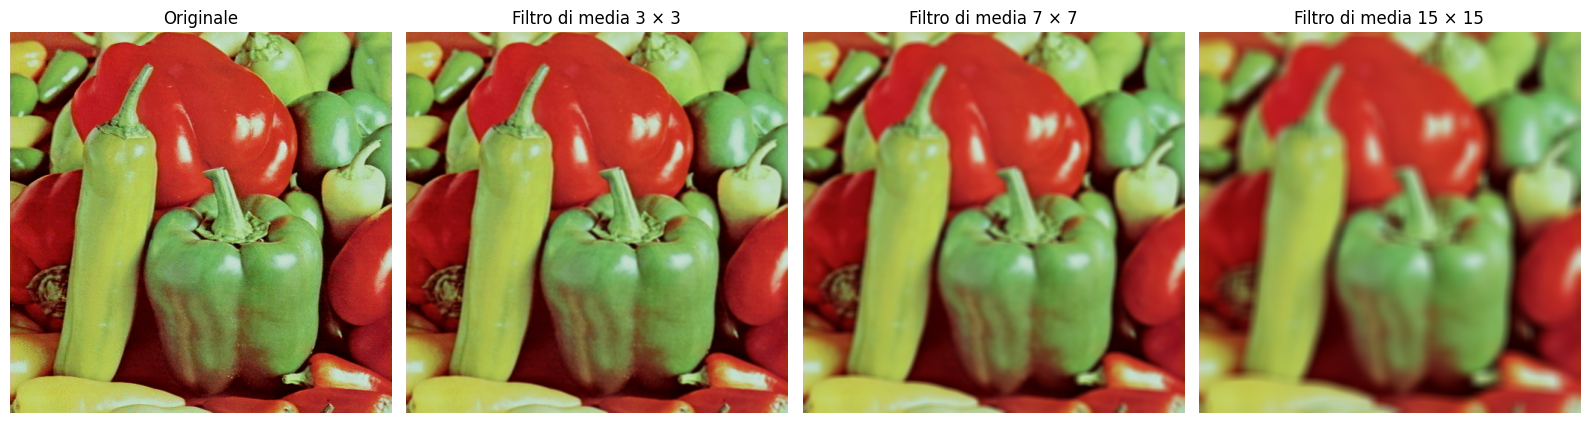

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

dimensioni = [3, 7, 15]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(img2)
axes[0].set_title("Originale")
axes[0].axis("off")

for ax, n in zip(axes[1:], dimensioni):

    # Kernel di media: la somma dei coefficienti è 1
    K = np.ones((n, n)) / n**2

    # Applica la convoluzione separatamente ai tre canali RGB
    img_filtrata = np.stack([
        convolve2d(
            img2[:, :, c],
            K,
            mode="same",       # Mantiene le dimensioni dell'immagine
            boundary="symm"     # Estensione simmetrica ai bordi
        )
        for c in range(3)
    ], axis=-1)

    ax.imshow(np.clip(img_filtrata, 0, 1))
    ax.set_title(f"Filtro di media {n} × {n}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Effetto della dimensione del filtro di media

Ogni filtro sostituisce il valore di un pixel con la **media dei valori in un intorno di $n \times n$ pixel**, separatamente per ciascun canale RGB. Il kernel è:

$$
K=\frac{1}{n^2}
\begin{pmatrix}
1 & \cdots & 1\\
\vdots & \ddots & \vdots\\
1 & \cdots & 1
\end{pmatrix}.
$$

Confrontando filtri di dimensione $3 \times 3$, $7 \times 7$ e $15 \times 15$, si osserva che, all'aumentare della dimensione del filtro, la media coinvolge pixel più lontani: **la sfocatura aumenta, i piccoli dettagli scompaiono e i contorni diventano meno netti**.

Il fattore $1/n^2$ mantiene la somma dei pesi uguale a $1$, preservando le intensità nelle regioni uniformi. In prossimità dei bordi, il risultato dipende anche dalla condizione al bordo scelta; nell'esempio si utilizza un'estensione simmetrica.
